In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Presuntos_Homicidios._Colombia,_2015_a_2024._Cifras_definitivas_20260916.csv")
print(f"Dataset: {len(df):,} filas × {df.shape[1]} columnas")
print(f"Períodos: {sorted(df['Año del hecho'].dropna().unique())}")
df.head(3)

Dataset: 125,284 filas × 33 columnas
Períodos: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


,ID,Año del hecho,Grupo de edad quinquenal,Grupo Mayor Menor de Edad,Grupo de Edad judicial,Ciclo Vital,Sexo de la victima,Estado Civil,País de Nacimiento,Escolaridad,...,Manera de muerte,Mecanismo Causal de la Lesión Fatal,Diagnostico Topográfico de la Lesión Fatal,Presunto Agresor Detallado,Localidad del Hecho,Ancestro Racial,Pueblo Indígena,Orientación Sexual,Identidad de Género,Transgénero
0,1,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Corto punzante,Trauma de abdomen,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
1,2,2015,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
2,3,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica secundaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada


## Paso 1 - Diagnostico

In [3]:

# 1. Nulos por columna (solo mostrar las que tienen nulos)
nulos = df.isna().sum()
nulos_pct = (df.isna().mean() * 100).round(2)

diag_nulos = pd.DataFrame({
    "n_nulos": nulos,
    "pct_nulos": nulos_pct
})

diag_nulos = diag_nulos[
    diag_nulos["n_nulos"] > 0
].sort_values("pct_nulos", ascending=False)

print("Columnas con nulos:")
print(diag_nulos.head(15))


# 2. Filas duplicadas
print(f"\nFilas duplicadas: {df.duplicated().sum():,}")


# 3. Rango de las variables numéricas
print("\nRango de las variables numéricas:")

columnas_numericas = df.select_dtypes(include=np.number).columns

for columna in columnas_numericas:
    print(
        f"{columna}: "
        f"{df[columna].min()} — {df[columna].max()}"
    )


Columnas con nulos:
Empty DataFrame
Columns: [n_nulos, pct_nulos]
Index: []

Filas duplicadas: 0

Rango de las variables numéricas:
ID: 1 — 125284
Año del hecho: 2015 — 2024
Código Dane Municipio: 999 — 99773
Código Dane Departamento: 5 — 999


In [4]:
# Revisar cuántas veces aparece "Sin información" en cada columna
sin_informacion = (
    df.apply(
        lambda columna: columna.astype("string")
        .str.strip()
        .str.casefold()
        .eq("sin información")
        .sum()
    )
)

sin_informacion = sin_informacion[
    sin_informacion > 0
].sort_values(ascending=False)

print("Columnas con la categoría 'Sin información':")
print(sin_informacion)

Columnas con la categoría 'Sin información':
Localidad del Hecho                           113810
Circunstancia del Hecho Detallada              80847
Rango de Hora del Hecho X 3 Horas              73982
Presunto Agresor Detallado                     65054
Actividad Durante el Hecho                     52747
Pertenencia Étnica                             47221
Escolaridad                                    26745
Pertenencia Grupal                             20741
Estado Civil                                   20184
Ancestro Racial                                10904
Escenario del Hecho                             7172
País de Nacimiento                              2076
Diagnostico Topográfico de la Lesión Fatal      1844
Zona del Hecho                                  1561
Mes del hecho                                    234
Dia del hecho                                    234
Municipio del hecho DANE                          98
Departamento del hecho DANE                       97
P

In [5]:
print("IDs duplicados:", df["ID"].duplicated().sum())
print("IDs únicos:", df["ID"].nunique())
print("Total de filas:", len(df))

IDs duplicados: 0
IDs únicos: 125284
Total de filas: 125284


In [6]:
# Contar "No había sido implementada" por columna
no_implementada = (
    df.astype("string")
      .apply(
          lambda col: col.str.strip()
                        .eq("No había sido implementada")
                        .sum()
      )
)

print(
    no_implementada[no_implementada > 0]
    .sort_values(ascending=False)
)

Orientación Sexual     83064
Identidad de Género    83064
Transgénero            83064
Pueblo Indígena        34490
dtype: int64


In [9]:
df_limpieza = df.copy()

df_limpieza = df_limpieza.replace(
    r"(?i)^\s*sin información\s*$",
    np.nan,
    regex=True
)
print("Total de valores nulos:", df_limpieza.isnull().sum().sum())

Total de valores nulos: 525641


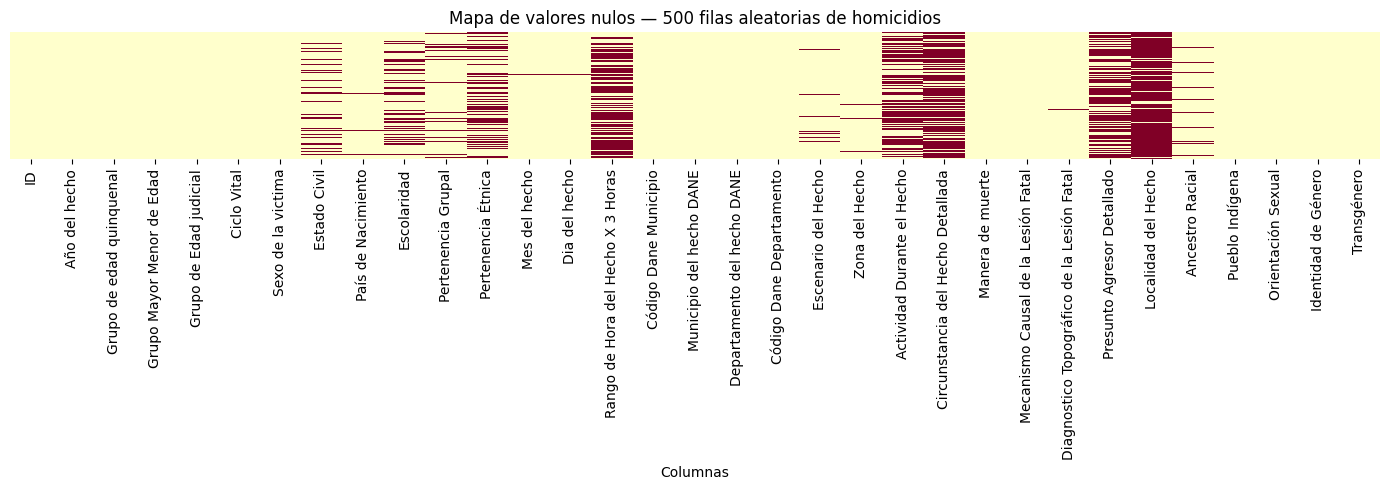

In [10]:
# Heatmap de nulos en una muestra de 500 filas
muestra_diag = df_limpieza.sample(500, random_state=42)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(
    muestra_diag.isna(),
    cbar=False,
    yticklabels=False,
    cmap="YlOrRd",
    ax=ax
)

ax.set_title("Mapa de valores nulos — 500 filas aleatorias de homicidios")
ax.set_xlabel("Columnas")
plt.tight_layout()
plt.show()

In [11]:
nulos = df_limpieza.isnull().sum()

nulos = nulos[nulos > 0].sort_values(ascending=False)

porcentaje_nulos = (
    df_limpieza.isnull().sum() / len(df_limpieza) * 100
)

resumen_nulos = pd.DataFrame({
    "Cantidad de nulos": nulos,
    "Porcentaje (%)": porcentaje_nulos[nulos.index].round(2)
})

print(resumen_nulos)

                                            Cantidad de nulos  Porcentaje (%)
Localidad del Hecho                                    113810           90.84
Circunstancia del Hecho Detallada                       80847           64.53
Rango de Hora del Hecho X 3 Horas                       73982           59.05
Presunto Agresor Detallado                              65054           51.93
Actividad Durante el Hecho                              52747           42.10
Pertenencia Étnica                                      47221           37.69
Escolaridad                                             26745           21.35
Pertenencia Grupal                                      20741           16.56
Estado Civil                                            20184           16.11
Ancestro Racial                                         10904            8.70
Escenario del Hecho                                      7172            5.72
País de Nacimiento                                       2076   

## Imputacion de nulos

In [13]:
# Imputar ESCENARIO DEL HECHO con la moda (es categórica)
df_ejemplo = df_limpieza.copy()

moda = df_ejemplo["Escenario del Hecho"].mode()[0]
n_antes = df_ejemplo["Escenario del Hecho"].isna().sum()

df_ejemplo["Escenario del Hecho"] = (
    df_ejemplo["Escenario del Hecho"].fillna(moda)
)

n_despues = df_ejemplo["Escenario del Hecho"].isna().sum()

print(f"Escenario del Hecho: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Escenario del Hecho: 7,172 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'Vía Pública'


In [14]:
# Imputar Municipio del hecho DANE con la moda
df_ejemplo = df_limpieza.copy()

moda = df_ejemplo["Municipio del hecho DANE"].mode()[0]
n_antes = df_ejemplo["Municipio del hecho DANE"].isna().sum()
df_ejemplo["Municipio del hecho DANE"] = df_ejemplo["Municipio del hecho DANE"].fillna(moda)
n_despues = df_ejemplo["Municipio del hecho DANE"].isna().sum()

print(f"Municipio del hecho DANE: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Municipio del hecho DANE: 98 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'Cali'


In [15]:
# Imputar Departamento del hecho DANE con la moda
moda = df_ejemplo["Departamento del hecho DANE"].mode()[0]
n_antes = df_ejemplo["Departamento del hecho DANE"].isna().sum()
df_ejemplo["Departamento del hecho DANE"] = df_ejemplo["Departamento del hecho DANE"].fillna(moda)
n_despues = df_ejemplo["Departamento del hecho DANE"].isna().sum()

print(f"Departamento del hecho DANE: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Departamento del hecho DANE: 97 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'Valle del Cauca'


In [21]:
# Imputar Mes del hecho con la moda
df_ejemplo = df_limpieza.copy()

moda = df_ejemplo["Mes del hecho"].mode()[0]
n_antes = df_ejemplo["Mes del hecho"].isna().sum()

df_ejemplo["Mes del hecho"] = df_ejemplo["Mes del hecho"].fillna(moda)

n_despues = df_ejemplo["Mes del hecho"].isna().sum()

print(f"Mes del hecho: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Mes del hecho: 234 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'diciembre'


## Detección de outliers


In [26]:
# Agrupar los homicidios usando únicamente el código DANE
homicidios_municipio = (
    df_limpieza.groupby("Código Dane Municipio")
    .agg(
        Cantidad_de_homicidios=("Código Dane Municipio", "size"),
        Municipio=("Municipio del hecho DANE", "first")
    )
    .reset_index()
)

print(homicidios_municipio.head())

   Código Dane Municipio  Cantidad_de_homicidios   Municipio
0                    999                      98         NaN
1                   5001                    4729    Medellín
2                   5002                      57   Abejorral
3                   5004                       1    Abriaquí
4                   5021                       8  Alejandría


In [31]:

# Excluir temporalmente los registros sin municipio identificado
municipios_validos = homicidios_municipio[
    homicidios_municipio["Código Dane Municipio"] != 999
].copy()
# Función para detectar outliers mediante IQR
def detectar_outliers_iqr(serie):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1

    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    return (serie < lim_inf) | (serie > lim_sup)

# Detectar posibles outliers
outliers = detectar_outliers_iqr(
    homicidios_municipio["Cantidad_de_homicidios"]
)

print(
    f"Cantidad de posibles outliers: {outliers.sum():,} "
    f"({outliers.mean() * 100:.2f}%)"
)

print(
    homicidios_municipio.loc[outliers]
    .sort_values("Cantidad_de_homicidios", ascending=False)
)

Cantidad de posibles outliers: 122 (11.23%)
      Código Dane Municipio  Cantidad_de_homicidios         Municipio
149                   11001                   11667      Bogotá, D.C.
978                   76001                   11408  Santiago de Cali
1                      5001                    4729          Medellín
126                    8001                    3846      Barranquilla
150                   13001                    2949         Cartagena
...                     ...                     ...               ...
786                   54553                     180  Puerto Santander
668                   50006                     178           Acacías
154                   13052                     178            Arjona
1011                  76823                     178              Toro
358                   19300                     176          Guachene

[122 rows x 3 columns]


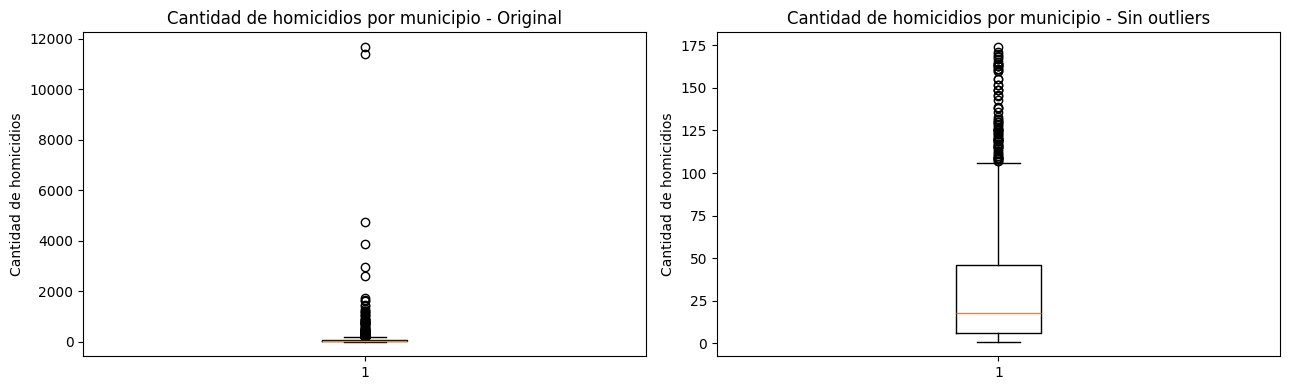

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Boxplot original
axes[0].boxplot(homicidios_municipio["Cantidad_de_homicidios"])
axes[0].set_title("Cantidad de homicidios por municipio - Original")
axes[0].set_ylabel("Cantidad de homicidios")

# Boxplot sin los posibles outliers
sin_out = homicidios_municipio.loc[
    ~outliers, "Cantidad_de_homicidios"
]

axes[1].boxplot(sin_out)
axes[1].set_title("Cantidad de homicidios por municipio - Sin outliers")
axes[1].set_ylabel("Cantidad de homicidios")

plt.tight_layout()
plt.show()

## Corrección de texto inconsistente

In [34]:
# Ver valores únicos de una columna de texto
print("Sexo de la victima valores únicos ANTES:")
print(df_limpieza["Sexo de la victima"].value_counts(dropna=False))

# Normalizar
df_limpieza["Sexo de la victima_LIMPIO"] = (
    df_limpieza["Sexo de la victima"].str.strip().str.upper()
)

print("\nSexo de la victima valores únicos DESPUÉS:")
print(df_limpieza["Sexo de la victima_LIMPIO"].value_counts(dropna=False))

Sexo de la victima valores únicos ANTES:
Sexo de la victima
Hombre           115147
Mujer             10030
Indeterminado       107
Name: count, dtype: int64

Sexo de la victima valores únicos DESPUÉS:
Sexo de la victima_LIMPIO
HOMBRE           115147
MUJER             10030
INDETERMINADO       107
Name: count, dtype: int64


In [35]:
# Ver valores únicos de una columna de texto
print("Mes del hecho valores únicos ANTES:")
print(df_limpieza["Mes del hecho"].value_counts(dropna=False))

# Normalizar
df_limpieza["Mes del hecho_LIMPIO"] = (
    df_limpieza["Mes del hecho"].str.strip().str.upper()
)

print("\nMes del hecho valores únicos DESPUÉS:")
print(df_limpieza["Mes del hecho_LIMPIO"].value_counts(dropna=False))

Mes del hecho valores únicos ANTES:
Mes del hecho
diciembre     9372
enero         8508
julio         8359
mayo          8281
agosto        8230
noviembre     8102
junio         8044
octubre       7996
marzo         7978
septiembre    7892
abril         7703
febrero       7326
Mayo          2523
Agosto        2427
Diciembre     2411
Junio         2352
Octubre       2347
Septiembre    2294
Julio         2288
Noviembre     2257
Enero         2238
Marzo         2069
Abril         2057
Febrero       1996
NaN            234
Name: count, dtype: int64

Mes del hecho valores únicos DESPUÉS:
Mes del hecho_LIMPIO
DICIEMBRE     11783
MAYO          10804
ENERO         10746
AGOSTO        10657
JULIO         10647
JUNIO         10396
NOVIEMBRE     10359
OCTUBRE       10343
SEPTIEMBRE    10186
MARZO         10047
ABRIL          9760
FEBRERO        9322
NaN             234
Name: count, dtype: int64


In [36]:
# Ver valores únicos de una columna de texto
print("Municipio del hecho DANE valores únicos ANTES:")
print(df_limpieza["Municipio del hecho DANE"].value_counts(dropna=False))

# Normalizar
df_limpieza["Municipio del hecho DANE_LIMPIO"] = (
    df_limpieza["Municipio del hecho DANE"].str.strip().str.upper()
)

print("\nMunicipio del hecho DANE valores únicos DESPUÉS:")
print(df_limpieza["Municipio del hecho DANE_LIMPIO"].value_counts(dropna=False))

Municipio del hecho DANE valores únicos ANTES:
Municipio del hecho DANE
Cali            9984
Bogotá, D.C.    8992
Medellín        4729
Barranquilla    3846
Bogotá D.C.     2674
                ... 
Taraira            1
Tuta               1
San Mateo          1
Arcabuco           1
Piedras            1
Name: count, Length: 1048, dtype: int64

Municipio del hecho DANE valores únicos DESPUÉS:
Municipio del hecho DANE_LIMPIO
CALI            9984
BOGOTÁ, D.C.    8992
MEDELLÍN        4729
BARRANQUILLA    3846
BOGOTÁ D.C.     2674
                ... 
TARAIRA            1
TUTA               1
SAN MATEO          1
ARCABUCO           1
PIEDRAS            1
Name: count, Length: 1044, dtype: int64


In [37]:
# Ver valores únicos de una columna de texto
print("Departamento del hecho DANE valores únicos ANTES:")
print(df_limpieza["Departamento del hecho DANE"].value_counts(dropna=False))

# Normalizar
df_limpieza["Departamento del hecho DANE_LIMPIO"] = (
    df_limpieza["Departamento del hecho DANE"].str.strip().str.upper()
)

print("\nDepartamento del hecho DANE valores únicos DESPUÉS:")
print(df_limpieza["Departamento del hecho DANE_LIMPIO"].value_counts(dropna=False))

Departamento del hecho DANE valores únicos ANTES:
Departamento del hecho DANE
Valle del Cauca                                             23491
Antioquia                                                   18852
Bogotá, D.C.                                                 8992
Atlántico                                                    6608
Cauca                                                        6258
Norte de Santander                                           5461
Bolívar                                                      4930
Cundinamarca                                                 4186
Nariño                                                       3660
Magdalena                                                    3382
Santander                                                    3357
Tolima                                                       2893
Huila                                                        2801
Meta                                                         278

In [39]:
# Ver valores únicos de una columna de texto
print("Zona del Hecho valores únicos ANTES:")
print(df_limpieza["Zona del Hecho"].value_counts(dropna=False))

# Normalizar
df_limpieza["Zona del Hecho_LIMPIO"] = (
    df_limpieza["Zona del Hecho"].str.strip().str.upper()
)

print("\nZona del Hecho valores únicos DESPUÉS:")
print(df_limpieza["Zona del Hecho_LIMPIO"].value_counts(dropna=False))

Zona del Hecho valores únicos ANTES:
Zona del Hecho
Cabecera municipal                                                 88108
Parte rural (vereda y campo)                                       29200
Centro poblado(corregimiento, inspección de policía y caserío)      3336
Centro poblado (corregimiento, inspección de policía y caserío)     3079
NaN                                                                 1561
Name: count, dtype: int64

Zona del Hecho valores únicos DESPUÉS:
Zona del Hecho_LIMPIO
CABECERA MUNICIPAL                                                 88108
PARTE RURAL (VEREDA Y CAMPO)                                       29200
CENTRO POBLADO(CORREGIMIENTO, INSPECCIÓN DE POLICÍA Y CASERÍO)      3336
CENTRO POBLADO (CORREGIMIENTO, INSPECCIÓN DE POLICÍA Y CASERÍO)     3079
NaN                                                                 1561
Name: count, dtype: int64


In [41]:
print(
    df_limpieza["Municipio del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="BOGOTÁ")
)

Municipio del hecho DANE_LIMPIO
BOGOTÁ, D.C.    8992
BOGOTÁ D.C.     2674
Name: count, dtype: int64


In [42]:
# Unificar nombres de Bogotá
df_limpieza["Municipio del hecho DANE_LIMPIO"] = (
    df_limpieza["Municipio del hecho DANE_LIMPIO"]
    .replace("BOGOTÁ D.C.", "BOGOTÁ, D.C.")
)

# Verificar la corrección
print("Municipio del hecho DANE_LIMPIO:")
print(
    df_limpieza["Municipio del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="BOGOTÁ")
)

Municipio del hecho DANE_LIMPIO:
Municipio del hecho DANE_LIMPIO
BOGOTÁ, D.C.    11666
Name: count, dtype: int64


In [43]:
# Unificar nombres inconsistentes de departamentos
df_limpieza["Departamento del hecho DANE_LIMPIO"] = (
    df_limpieza["Departamento del hecho DANE_LIMPIO"]
    .replace({
        "BOGOTÁ D.C.": "BOGOTÁ, D.C.",
        "QUINDIO": "QUINDÍO"
    })
)

# Verificar las correcciones
print("Departamentos corregidos:")
print(
    df_limpieza["Departamento del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="BOGOTÁ")
)
print(
    df_limpieza["Departamento del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="QUIND")
)

Departamentos corregidos:
Departamento del hecho DANE_LIMPIO
BOGOTÁ, D.C.    11666
Name: count, dtype: int64
Departamento del hecho DANE_LIMPIO
QUINDÍO    1999
Name: count, dtype: int64


## Normalización de escalas